# 03. Каузальная предобработка, базовая модель, честные разбиения

**Вопрос этапа (PROJECT_PLAN.md, этап 3):** насколько падает качество распознавания жестов при переходе
на другой день и на другого человека?

Цепочка обработки:
**сырой сигнал → каузальный фильтр 20–450 Гц → окна 200 мс → признаки Хаджинса → классификатор → жест окна.**

Расчёт — эксперимент `python run.py --config configs/baseline_dev.yaml`
(код: `src/preprocess.py`, `features.py`, `splits.py`, `models.py`, `evaluate.py`).
Ноутбук объясняет каждый шаг и разбирает результаты.

In [6]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from scipy import signal
from IPython.display import Image, display

from data import build_index, FS, GESTURE_SHORT
from preprocess import design_filter, filter_causal
from features import feature_table, feature_names
import viz
viz.setup()
pd.set_option("display.width", 160)

cfg = yaml.safe_load((ROOT / "configs" / "baseline_dev.yaml").read_text(encoding="utf-8"))
pre = cfg["preprocess"]
sos = design_filter(band_hz=tuple(pre["band_hz"]), order=pre["order"], notch_hz=tuple(pre["notch_hz"]))

## 1. Каузальный фильтр

**Термины:**
- **Фильтр** ослабляет одни частоты и пропускает другие. Пропускаем 20–450 Гц, где лежит ЭМГ;
  убираем то, что ниже (движение электрода, дрейф контакта), и то, что выше.
- **Каузальный** фильтр: выход в момент *t* зависит только от входа **до** момента *t*. Браслет в реальном времени
  будущего не знает, поэтому другим фильтр в нашей задаче быть не может.
- **БИХ-фильтр** (IIR) использует не только прошлые входы, но и свои прошлые выходы:
  $y[n] = \sum_k b_k x[n-k] - \sum_k a_k y[n-k]$. Крутой срез частот за малое число операций — удобно для устройства.
- **Баттерворт** — вид БИХ-фильтра с максимально ровным усилением внутри полосы пропускания.
- **SOS** (second-order sections) — тот же фильтр, записанный цепочкой маленьких фильтров 2-го порядка.
  Математически то же самое, но без ошибок округления, которые появляются, если считать высокий порядок одним куском.
- **Состояние фильтра** (`zi`) — его память: последние внутренние значения. Чтобы фильтровать поток кусками,
  состояние с конца куска передаём в начало следующего. Результат совпадает с фильтрацией целиком (проверено в коде).
- **Групповая задержка** — на сколько фильтр запаздывает сигнал на данной частоте. Каузальный фильтр всегда запаздывает;
  вопрос — насколько.

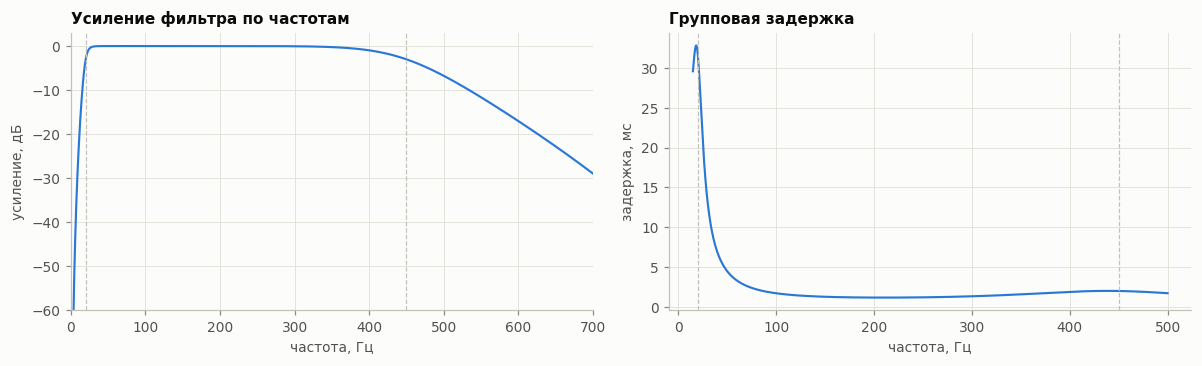

,"частота, Гц","усиление, дБ","задержка, мс"
0,20,-3.01,31.7
1,30,-0.11,13.2
2,40,-0.01,6.8
3,60,-0.00,3.3
4,100,-0.00,1.7
5,200,-0.00,1.2
6,300,-0.04,1.3
7,450,-3.01,2.0


In [7]:
f, h = signal.sosfreqz(sos, worN=2**16, fs=FS)
gd_ms = -np.gradient(np.unwrap(np.angle(h)), 2 * np.pi * f) * 1000

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(f, 20 * np.log10(np.abs(h) + 1e-12), color=viz.SERIES[0])
axes[0].set_xlim(0, 700); axes[0].set_ylim(-60, 3)
axes[0].set_xlabel("частота, Гц"); axes[0].set_ylabel("усиление, дБ")
axes[0].set_title("Усиление фильтра по частотам")
sel = (f > 15) & (f < 500)
axes[1].plot(f[sel], gd_ms[sel], color=viz.SERIES[0])
axes[1].set_xlabel("частота, Гц"); axes[1].set_ylabel("задержка, мс")
axes[1].set_title("Групповая задержка")
for ax in axes:
    for edge in pre["band_hz"]:
        ax.axvline(edge, color=viz.AXIS, lw=0.8, ls="--")
fig.tight_layout()
viz.save(fig, "03_filter_response")
plt.show()

pd.DataFrame({"частота, Гц": q, "усиление, дБ": round(20 * np.log10(abs(h[np.argmin(abs(f - q))])), 2),
              "задержка, мс": round(gd_ms[np.argmin(abs(f - q))], 1)} for q in [20, 30, 40, 60, 100, 200, 300, 450])

**Как читать:**
- Внутри 40–450 Гц усиление ровное (0 дБ), на краях 20 и 450 Гц ослабление −3 дБ (так по определению задаются края полосы).
- Задержка в основной полосе ЭМГ (40–450 Гц) — **1–7 мс**. У нижнего края она растёт до ~32 мс на 20 Гц, но там мало энергии ЭМГ.

**Вывод:** фильтр добавляет к задержке системы единицы миллисекунд. Это мало рядом с окном 200 мс (раздел 3).

## 2. Почему нельзя `filtfilt`

`filtfilt` прогоняет фильтр по сигналу вперёд, а потом назад по времени. Задержки двух проходов взаимно сокращаются —
для офлайн-анализа это удобно. Но проход назад использует **будущие** отсчёты.

Демонстрация: тишина, а с 0,5 с начинается шумоподобный всплеск, похожий на ЭМГ.

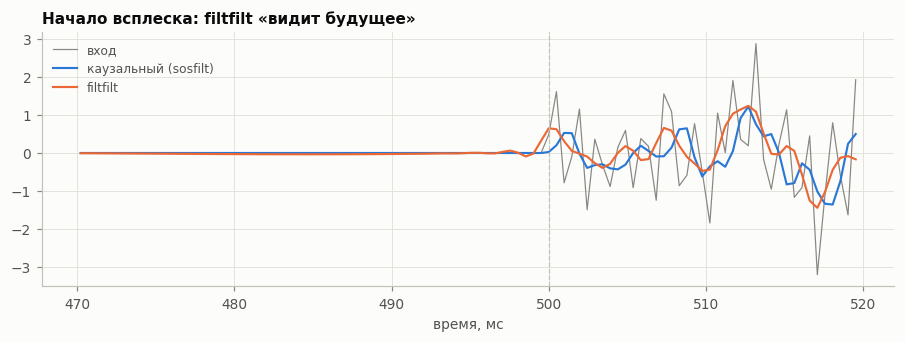

энергия выхода ДО начала всплеска: каузальный 0.00e+00, filtfilt 1.51e-01


In [8]:
rng = np.random.default_rng(0)
t = np.arange(int(1.0 * FS)) / FS
x = np.where(t >= 0.5, rng.standard_normal(len(t)), 0.0)[:, None]
y_causal, _ = filter_causal(x, sos)
y_ff = signal.sosfiltfilt(sos, x, axis=0)

fig, ax = plt.subplots(figsize=(10, 3))
sel = (t > 0.47) & (t < 0.52)
ax.plot(t[sel] * 1000, x[sel, 0], color=viz.REFERENCE, lw=0.8, label="вход")
ax.plot(t[sel] * 1000, y_causal[sel, 0], color=viz.SERIES[0], label="каузальный (sosfilt)")
ax.plot(t[sel] * 1000, y_ff[sel, 0], color=viz.SERIES[1], label="filtfilt")
ax.axvline(500, color=viz.AXIS, lw=0.8, ls="--")
ax.set_xlabel("время, мс"); ax.legend(fontsize=8, loc="upper left")
ax.set_title("Начало всплеска: filtfilt «видит будущее»")
viz.save(fig, "03_causal_vs_filtfilt")
plt.show()

before = t < 0.5
print(f"энергия выхода ДО начала всплеска: каузальный {np.sum(y_causal[before] ** 2):.2e}, filtfilt {np.sum(y_ff[before] ** 2):.2e}")

**Как читать:** каузальный выход до 500 мс равен нулю — фильтр не может отреагировать на то, чего ещё не было.
У `filtfilt` колебания появляются за несколько миллисекунд **до** события: проход назад «протащил» будущее в прошлое.
Здесь эффект небольшой, но принцип важен: при сглаживании огибающей или длинных фильтрах заглядывание вперёд
растёт до десятков и сотен миллисекунд.

Модель, обученная и проверенная на таком сигнале, получает информацию, которой у браслета не будет, и её точность
и задержка окажутся нереалистично хорошими.

## 3. Окна и шаг

- **Окно** — последние 200 мс сигнала. По нему считаем признаки и принимаем одно решение «какой жест».
- **Шаг** — как часто принимаем решение: каждые 50 мс. Соседние окна перекрываются на 150 мс.

**Компромисс:** чем длиннее окно, тем стабильнее признаки (меньше случайных колебаний), но тем позже модель замечает новый жест.
Часто цитируемый ориентир полной задержки для ЭМГ-управления — около 300 мс.

Две детали:
- **Метка окна = метка попытки.** На этапе 1 выяснили, что жест удерживается всю 5-секундную попытку.
- **Первые 200 мс каждой попытки выбрасываем.** Попытка — отдельный файл, и фильтр в её начале стартует «с нуля».
  В непрерывном потоке браслета такого старта нет. Остаётся **93 окна на попытку**.

## 4. Признаки Хаджинса

Из каждого окна каждого канала считаем 5 чисел (*x* — отфильтрованный сигнал внутри окна):

| Признак | Формула | Что значит простыми словами |
|---|---|---|
| MAV | среднее $\lvert x\rvert$ | насколько сильно работает мышца под электродом |
| RMS | $\sqrt{\text{среднее } x^2}$ | то же, но с бо́льшим весом пиков |
| WL (длина волны) | $\sum \lvert x[i]-x[i-1]\rvert$ | «длина нити», если вытянуть график: растёт и от амплитуды, и от частоты колебаний |
| ZC | число переходов через ноль | насколько часто колеблется сигнал (частота) |
| SSC | число смен наклона (вверх ↔ вниз) | тоже частота, чувствительнее к мелким колебаниям |

У ZC и SSC есть **порог** (0,01 мВ ≈ 1,5 × шум покоя из этапа 2): мелкие колебания шума не считаются.

Итого 5 × 12 каналов = **60 чисел на окно**.

**Почему это работает:** разные жесты включают разные мышцы, поэтому сила сигнала по 12 каналам распределяется по-разному.
Ниже — медианный RMS по каналам для каждого жеста у одного участника.

166005 окон, 60 признаков


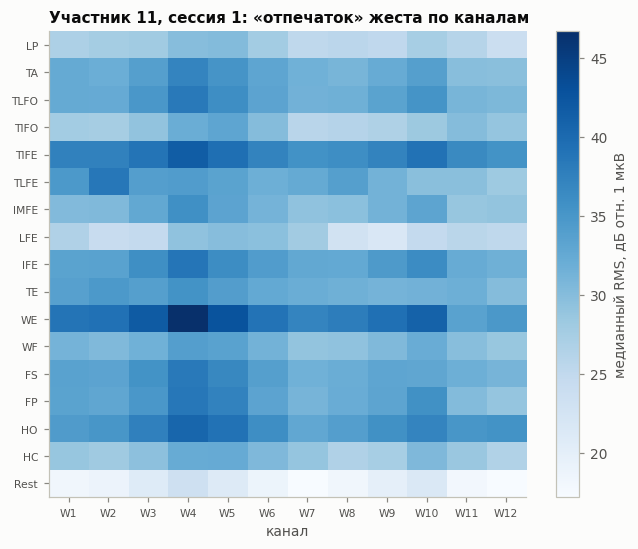

In [9]:
idx = build_index()
idx = idx[idx.participant.isin(yaml.safe_load((ROOT / "configs" / "splits.yaml").read_text())["dev"])]
channels = [f"W{i + 1}" for i in range(12)]
table = feature_table(idx, {**pre, **cfg["features"]}, channels)      # cached by run.py / earlier call
print(f"{len(table)} окон, {len(feature_names(channels))} признаков")

one = table[(table.participant == 11) & (table.session == 1)]
rms_db = 20 * np.log10(one.groupby("gesture")[[f"RMS_{c}" for c in channels]].median() * 1000)   # dB re 1 uV

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(rms_db.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(12), channels, fontsize=7)
ax.set_yticks(range(17), GESTURE_SHORT, fontsize=7)
ax.set_xlabel("канал"); ax.grid(False)
fig.colorbar(im, ax=ax, label="медианный RMS, дБ отн. 1 мкВ")
ax.set_title("Участник 11, сессия 1: «отпечаток» жеста по каналам")
viz.save(fig, "03_gesture_rms_p11_s1")
plt.show()

**Как читать:** каждая строка — «отпечаток» жеста на 12 каналах. Классификатор учится различать именно эти отпечатки
(плюс частотные признаки).
- Покой (Rest) — самая светлая строка: его отличить легко.
- Жесты сильно различаются по **общему уровню**: разгибание кисти (WE), разгибание большого и указательного (TIFE),
  раскрытие кисти (HO) — самые сильные; разгибание мизинца (LFE), боковой захват (LP) — самые слабые.
- **Форма** строк у многих жестов похожа: максимум на W4–W5 и W10. Значит, часть различий между жестами — это уровень,
  а не рисунок по каналам. Жесты с похожей формой и похожим уровнем будут путаться.
- Связь с этапом 2: если в новый день меняется общий масштаб амплитуды, «уровневые» различия между жестами сдвигаются.
  Это одна из причин ожидать падения в E2.

## 5. Честные разбиения E1–E4

| Эксперимент | Обучение | Тест | Что проверяет |
|---|---|---|---|
| E1. Внутри сессии | попытки 1–5 | попытки 6–7 той же сессии | потолок: тот же человек, то же надевание |
| E2. Между днями | сессия 1 | сессии 2 и 3 того же человека | новое надевание браслета |
| E3. Между людьми | другие люди, все сессии | новый человек | другая анатомия |
| E4. Люди + дни | другие люди, сессия 1 | новый человек, сессии 2–3 | оба сдвига сразу |

**Почему нельзя делить случайно по окнам.** Соседние окна перекрываются на 75 % и почти одинаковы. При случайном
разбиении почти-копия каждого тестового окна попадёт в обучение, модель «узнает» его, и точность будет завышена.
Поэтому делим только по попыткам, сессиям и людям.

**Ограничение dev-прогона.** Сейчас скачаны только 5 dev-участников. В E3 и E4 каждый из них по очереди становится
тестовым, а модель учится на остальных 4 (leave-one-participant-out). В плане обучение на ~33 людях, поэтому
межличностные результаты dev-прогона будут **заниженными**. Финальный прогон — на всех 43 с отложенными тестовыми участниками.

**Метрики.**
- **Balanced accuracy** — средняя по 17 жестам доля верно распознанных окон этого жеста. Каждый жест весит одинаково.
  Случайное угадывание даёт 1/17 ≈ 6 %.
- **Macro-F1** — среднее по жестам F1; дополнительно наказывает за ложные предсказания жеста.

**Модели** (сначала простая):
- **LDA** (линейный дискриминантный анализ) считает каждый жест облаком точек одинаковой формы, но с разным центром,
  и проводит между облаками прямые границы. Быстрый, стандартная база в ЭМГ.
- **LightGBM** — бустинг деревьев решений: умеет нелинейные границы.

Перед обеими моделями признаки стандартизуются (вычесть среднее, разделить на SD); среднее и SD считаются **только по обучающей части**.

## 6. Прогноз (до запуска)

Записан в `reports/notes.md` до запуска эксперимента.

## 7. Результаты

finished 2026-10-26T20:06:36


,experiment,model,median,min,max
0,E1,lda,85.6,81.5,88.6
1,E1,lgbm,79.7,77.5,83.4
2,E2,lda,34.4,26.2,69.4
3,E2,lgbm,54.4,44.3,66.4
4,E3,lda,30.7,26.0,38.5
5,E3,lgbm,30.9,25.0,33.7
6,E4,lda,31.6,21.6,37.4
7,E4,lgbm,29.0,20.9,33.8


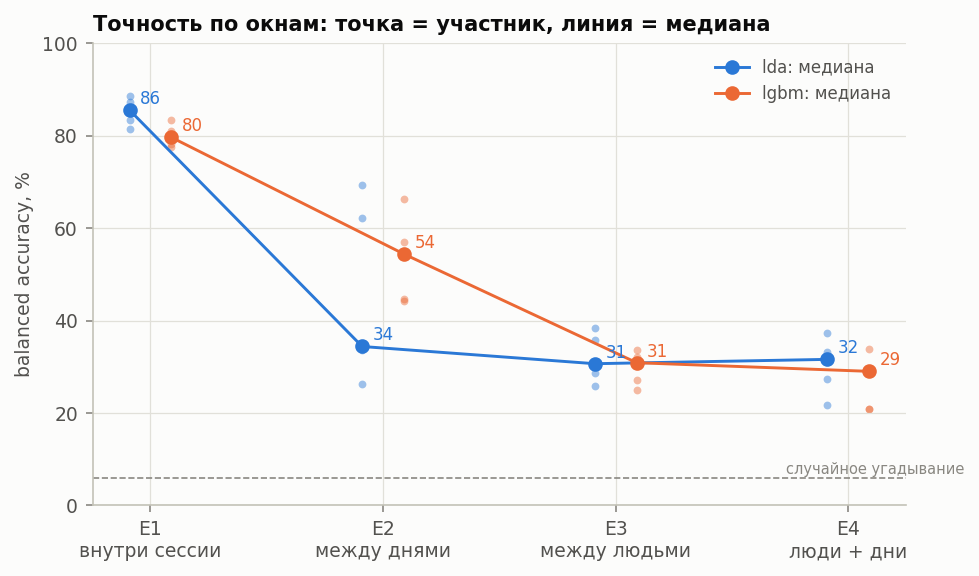

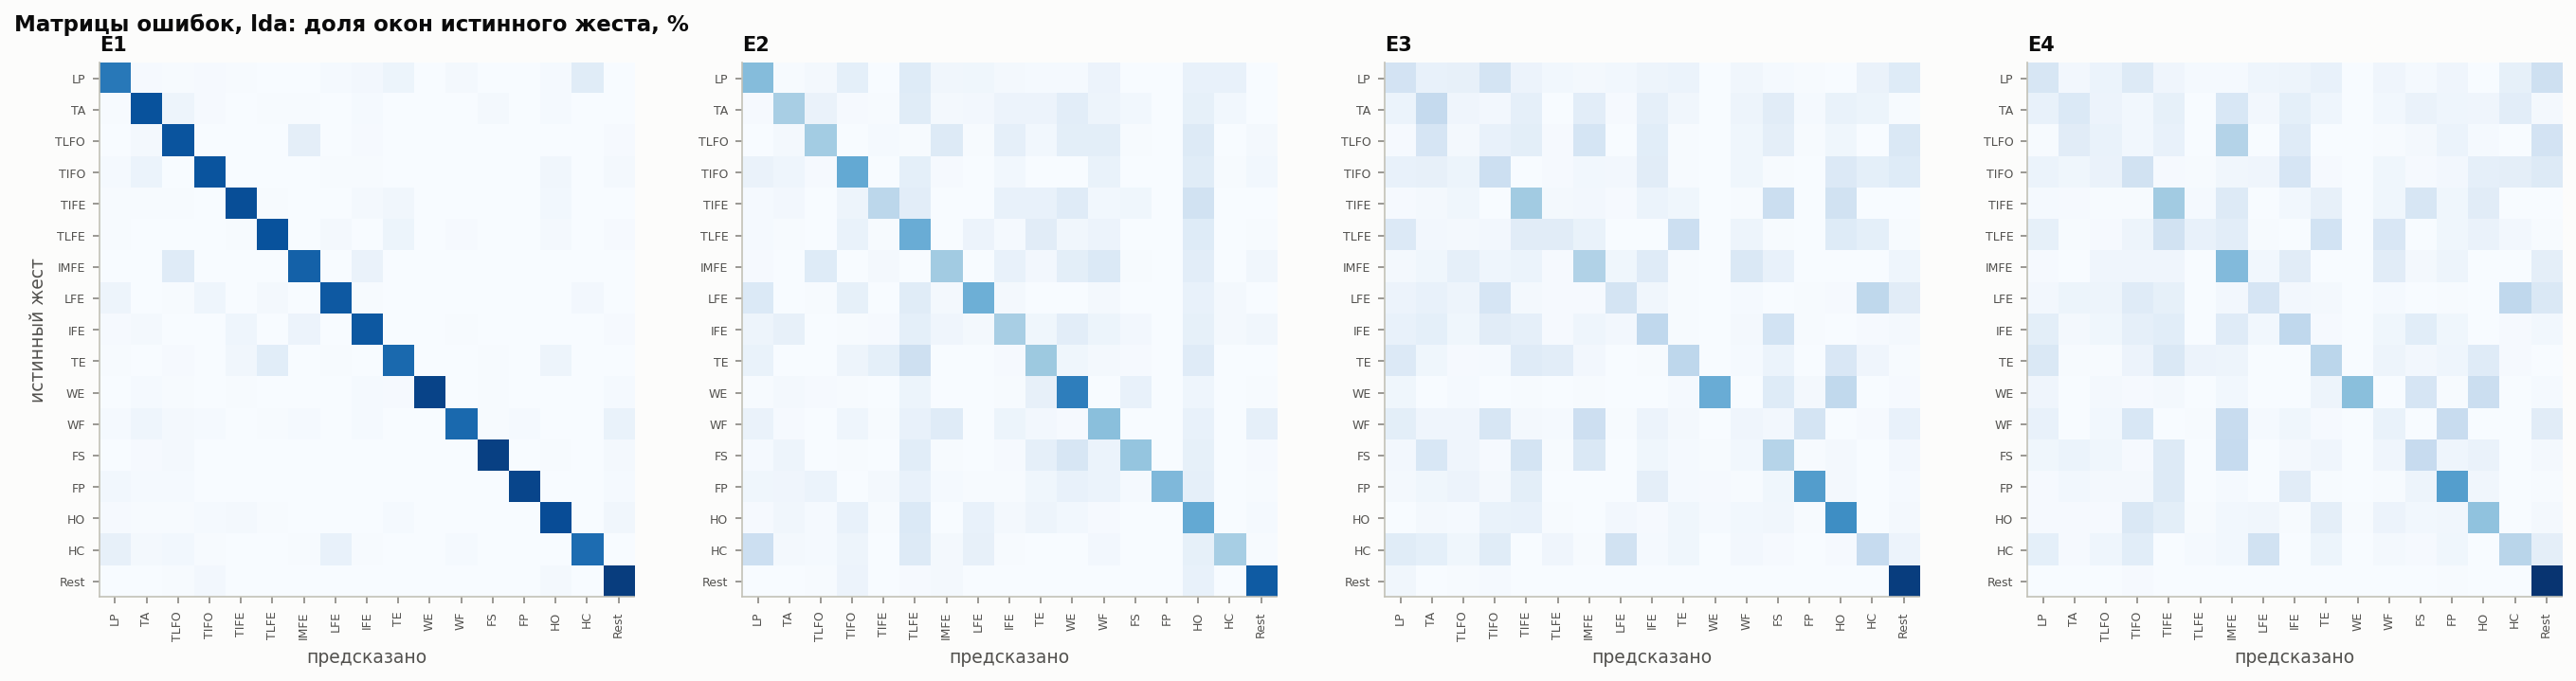

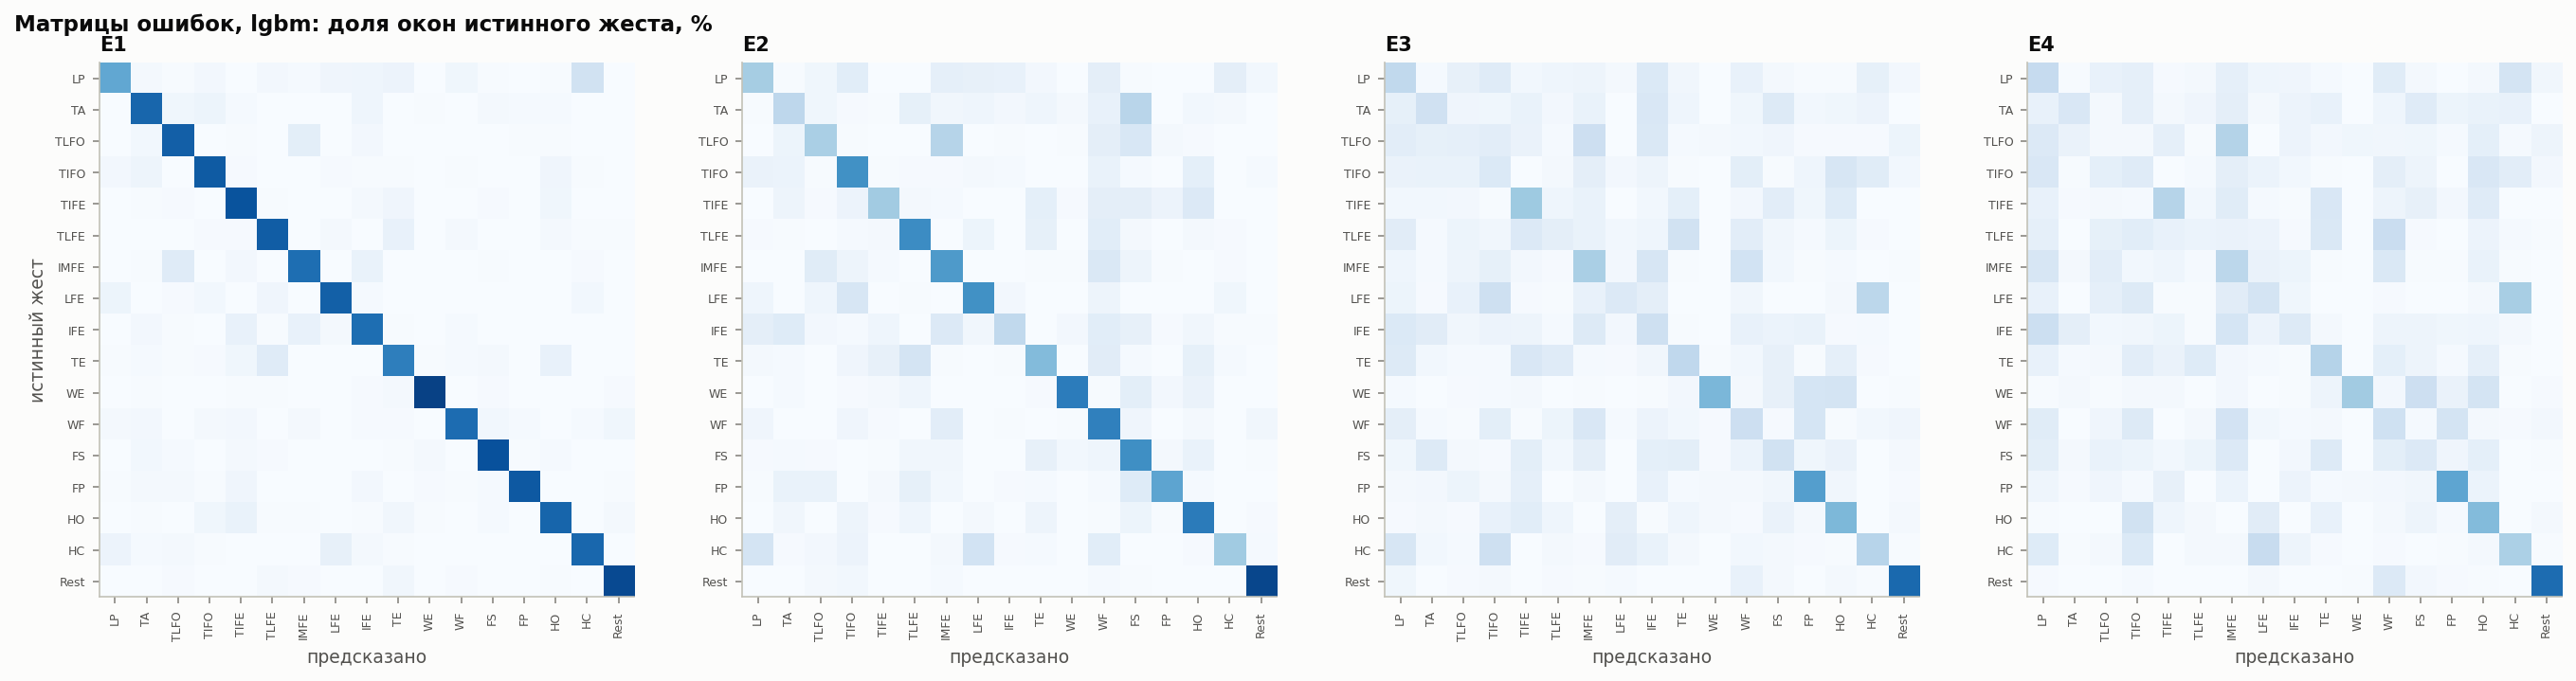

In [11]:
res_path = ROOT / "results" / "baseline_dev.json"
if not res_path.exists():
    print("Результатов ещё нет: запустите python run.py --config configs/baseline_dev.yaml")
else:
    res = json.loads(res_path.read_text(encoding="utf-8"))
    print("finished", res["finished"])
    s = pd.DataFrame(res["bal_acc_summary"])
    s[["median", "min", "max"]] *= 100
    display(s.round(1))
    for fig_path in res["figures"]:
        display(Image(ROOT / fig_path))